# Fusion: random forest + CNN

Interactive companion to `reports/fusion/README.md` (the written report with all figures).
The meta-learner is fitted by the pipeline, not here:

    python -m forest_fire_risk.fusion             # fit on 2020, evaluate on 2021-22 -> reports/fusion/
    python -m forest_fire_risk.fusion_figures     # figures

This notebook loads those results and shows how to work with them. Unlike the tabular and CNN
notebooks, **every cell runs without the raw data, the tiles or a GPU**: fusion only needs the
two committed prediction files, `reports/tabular/predictions.csv` and `reports/cnn/predictions.csv`.

| Years | Role here |
|---|---|
| 2017-2019 | not used (the base models were trained on it) |
| 2020 | fit the meta-learner; 5-fold CV inside 2020 picks its settings and threshold |
| 2021-2022 | test, scored once, at the end |

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

from forest_fire_risk.fusion import INPUTS, REPORT_DIR, fit_meta, load_predictions, logit
from forest_fire_risk.tabular import scores, season_weights

FIG = REPORT_DIR / "figures"
pd.set_option("display.precision", 3)

## 1. The inputs: one RF and one CNN probability per sample

`load_predictions` joins the two files on `sample_id` and fails if they do not hold exactly
the same samples, labels and splits.

In [2]:
df = load_predictions()
fit_rows = df[df.split == "val"].reset_index(drop=True)      # 2020
test = df[df.split == "test"].reset_index(drop=True)         # 2021-22
pd.crosstab(df.split.map({"val": "2020 (fit fusion)", "test": "2021-22 (test)"}), df.label,
            margins=True).rename(columns={0: "no fire", 1: "fire"})

label,no fire,fire,All
split,,,
2020 (fit fusion),1357,741,2098
2021-22 (test),2439,1319,3758
All,3796,2060,5856


How similar are the two base models? A correlation near 1 would mean they say the same thing
and fusion has nothing to add. Around 0.6 they often disagree, which is what makes combining
them worthwhile. On the logit scale the CNN's extreme probabilities (as low as 2e-5) are spread
out instead of squashed against 0.

In [3]:
pd.DataFrame({"probabilities": df.groupby("split").apply(lambda g: g.p_rf.corr(g.p_cnn)),
              "logits": df.groupby("split").apply(lambda g: pd.Series(logit(g.p_rf)).corr(pd.Series(logit(g.p_cnn))))})

,probabilities,logits
split,,
test,0.589,0.555
val,0.635,0.594


In [4]:
df.groupby(["split", "label"])[INPUTS].describe().T.loc[(slice(None), ["min", "50%", "max"]), :]

split           test                   val           
label              0          1          0          1
p_rf  min  0.000e+00  2.025e-02  0.000e+00  2.326e-02
      50%  1.785e-01  6.313e-01  1.482e-01  6.378e-01
      max  9.253e-01  9.784e-01  8.825e-01  9.877e-01
p_cnn min  2.110e-07  4.900e-05  4.106e-08  9.335e-06
      50%  3.285e-02  8.931e-01  2.383e-02  9.033e-01
      max  1.000e+00  1.000e+00  9.997e-01  1.000e+00

## 2. Chosen settings (from cross-validation inside 2020)

$p_{final} = \sigma(w_0 + w_{rf}\, z_{rf} + w_{cnn}\, z_{cnn})$, with $z$ the standardised
logit of each base model, so the two weights are "change in log-odds of fire per standard
deviation" and can be compared directly.

In [5]:
meta = json.loads((REPORT_DIR / "meta_learner.json").read_text())
pd.Series({"input scale": meta["input"], "C": meta["C"], "CV AUPRC (2020)": round(meta["cv_auprc"], 3),
           "threshold": round(meta["threshold"], 3), "w0 (intercept)": round(meta["intercept"], 3),
           "w_rf": round(meta["weights"]["p_rf"], 3), "w_cnn": round(meta["weights"]["p_cnn"], 3)})

input scale        logit
C                    100
CV AUPRC (2020)    0.891
threshold          0.384
w0 (intercept)    -1.346
w_rf               2.126
w_cnn              1.257
dtype: object

Every setting tried: the logit scale beats raw probabilities for every C, and C hardly matters
from 0.1 upwards (only two inputs, so there is little to regularise).

In [6]:
cv = pd.read_csv(REPORT_DIR / "cv_results.csv")
cv.pivot(index="param_logisticregression__C", columns="input", values="mean_test_score").rename_axis("C")

input,logit,prob
C,,
0.001,0.889,0.882
0.010,0.890,0.884
0.100,0.891,0.884
1.000,0.891,0.884
10.000,0.891,0.884
100.000,0.891,0.884


## 3. Test results (2021-22), standard and season-matched

Season-matched = test non-fires re-weighted so their months follow the fires' months, which
removes the "fire season" shortcut (random guessing: AUPRC 0.351).
"Average" is a fusion that learns nothing: $(p_{rf} + p_{cnn})/2$.

In [7]:
metrics = pd.read_csv(REPORT_DIR / "metrics.csv")
metrics.pivot(index="model", columns="evaluation", values=["auprc", "roc_auc", "f1"]).loc[
    ["fusion", "average", "rf", "cnn"]]

auprc                 roc_auc                      f1  \
evaluation season_matched standard season_matched standard season_matched   
model                                                                       
fusion              0.793    0.864          0.864    0.917          0.697   
average             0.786    0.846          0.852    0.901          0.687   
rf                  0.731    0.829          0.831    0.899          0.671   
cnn                 0.705    0.749          0.810    0.843          0.657   

                     
evaluation standard  
model                
fusion        0.780  
average       0.750  
rf            0.758  
cnn           0.695

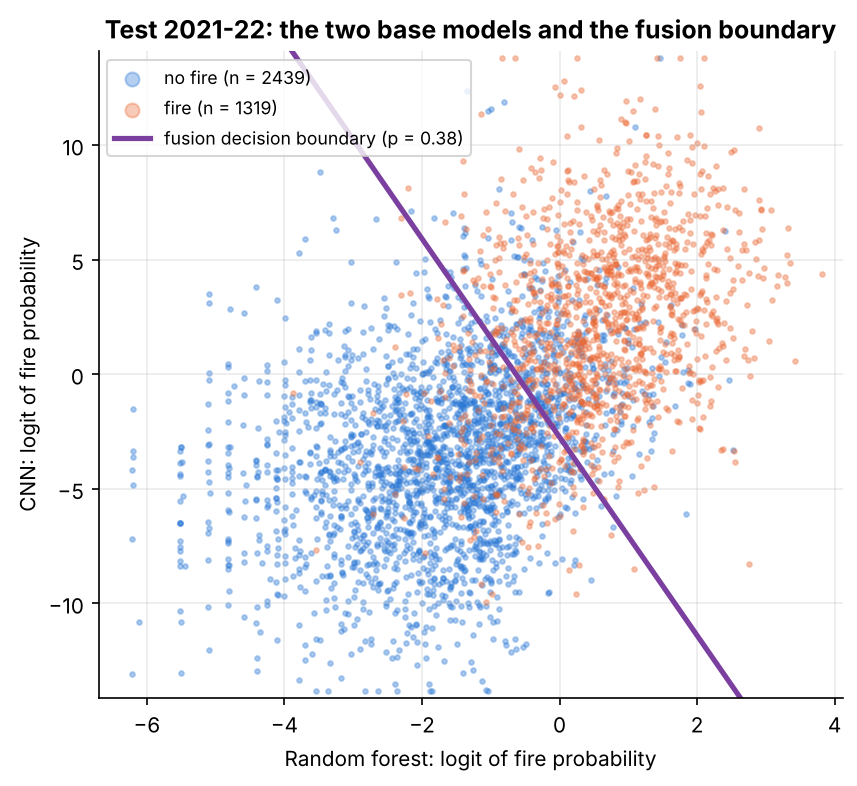

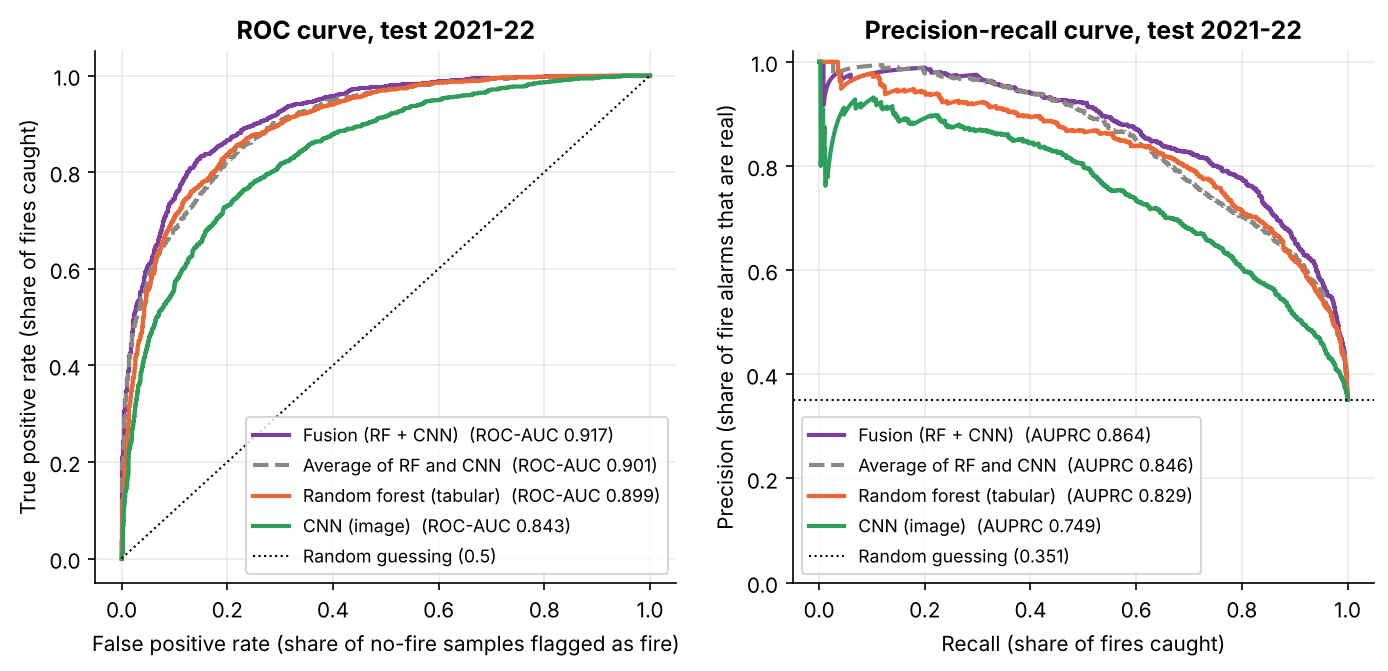

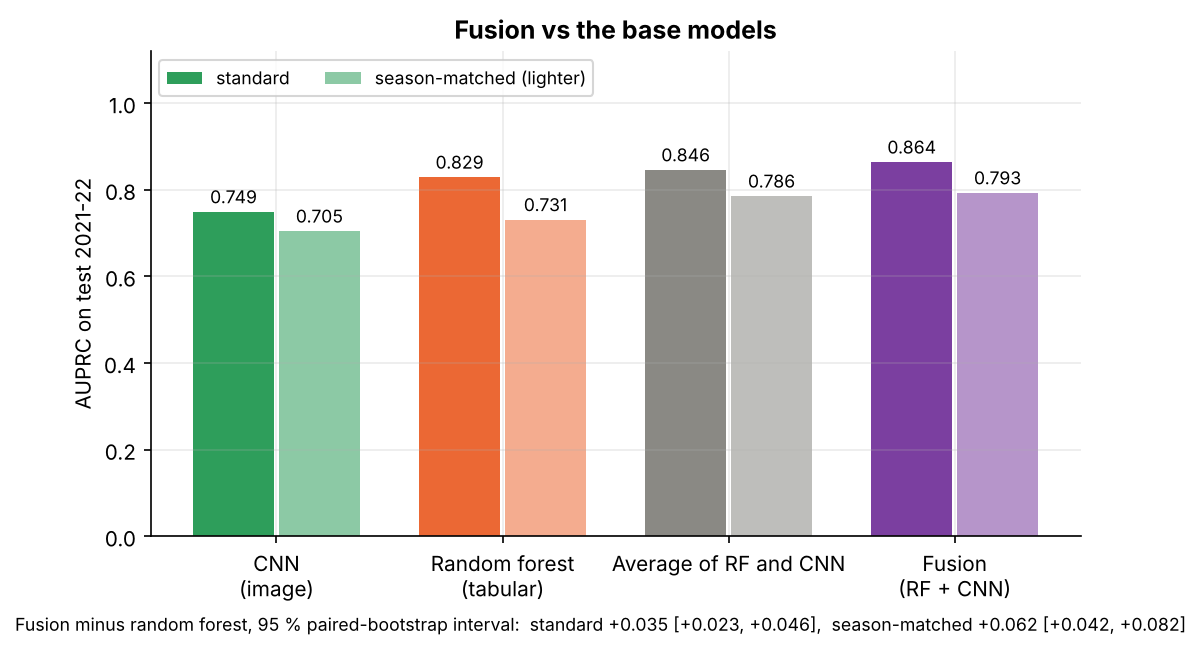

In [8]:
for f in ["01_scatter_boundary.png", "02_roc_pr_curves.png", "03_auprc_bars.png"]:
    display(Image(FIG / f))

## 4. Refit the meta-learner live

The meta-learner has three parameters and 2,098 training rows, so refitting takes seconds.
The test scores below are recomputed from scratch and should match the table above.

In [9]:
fit = fit_meta(fit_rows)
p_fusion = fit["model"].predict_proba(test[INPUTS])[:, 1]
w = season_weights(test.label, test.month)
pd.DataFrame({"standard": scores(test.label, p_fusion, fit["threshold"]),
              "season_matched": scores(test.label, p_fusion, fit["threshold"], w)})

,standard,season_matched
auprc,0.864,0.793
roc_auc,0.917,0.864
f1,0.780,0.697
precision,0.726,0.594
recall,0.842,0.842
threshold,0.384,0.384


Scoring a single new sample needs only its two base-model probabilities:

In [10]:
example = pd.DataFrame({"p_rf": [0.45, 0.45, 0.20, 0.20], "p_cnn": [0.05, 0.90, 0.95, 0.9999]})
example.assign(p_fusion=fit["model"].predict_proba(example)[:, 1],
               predicted_fire=lambda d: d.p_fusion >= fit["threshold"])

,p_rf,p_cnn,p_fusion,predicted_fire
0,0.45,0.05,0.320,False
1,0.45,0.90,0.647,True
2,0.20,0.95,0.365,False
3,0.20,1.00,0.750,True


Rows 1-2: same lukewarm random forest (0.45), opposite image evidence, and the CNN decides.
Rows 3-4: the random forest leans towards "no fire" (0.20). A CNN at 0.95 is not enough to
overrule it: the CNN is overconfident and says 0.95 or more for 17 % of the 2020 samples (42 % of
the fires), so 0.95 is ordinary evidence for this model. Only an extreme value (0.9999, under 1 %
of samples) flips the answer. This is what the logit scale buys:
0.95 and 0.9999 look almost equal as probabilities but are far apart as logits (2.9 vs 9.2).

## 5. Is the gain real?

Paired bootstrap: resample the 3,758 test samples with replacement 2,000 times and recompute
"fusion AUPRC minus base-model AUPRC" each time. If the 95 % interval stays above zero, the
gain is not luck in which test samples we happen to have. (It does not cover the CNN's own
run-to-run variance of about +-0.02-0.03; see the report.)

In [11]:
boot = pd.read_csv(REPORT_DIR / "bootstrap.csv").set_index("vs")
pd.DataFrame({ev: boot.apply(lambda r: f"{r[ev + '_mean']:+.3f}  [{r[ev + '_ci_low']:+.3f}, {r[ev + '_ci_high']:+.3f}]",
                             axis=1) for ev in ["standard", "season_matched"]}).rename(
    index={"rf": "fusion minus RF", "cnn": "fusion minus CNN"})

,standard,season_matched
vs,,
fusion minus CNN,"+0.114 [+0.097, +0.132]","+0.087 [+0.064, +0.113]"
fusion minus RF,"+0.035 [+0.023, +0.046]","+0.062 [+0.042, +0.082]"


## 6. Where fusion changes the decision

Compare the random forest alone (its own threshold, 0.369) with fusion (threshold from 2020) on
each test sample. Most samples get the same answer; the interesting ones are the switches.

In [12]:
rf_thr = json.loads((REPORT_DIR / "meta_learner.json").read_text())["thresholds_used"]["rf"]
cmp = test.assign(rf_says=test.p_rf >= rf_thr, fusion_says=p_fusion >= fit["threshold"])
cmp["change"] = np.select(
    [cmp.rf_says == cmp.fusion_says, ~cmp.rf_says & cmp.fusion_says],
    ["same answer", "RF: no fire -> fusion: fire"], "RF: fire -> fusion: no fire")
cmp["fusion_right"] = cmp.fusion_says == cmp.label.astype(bool)
summary = cmp.groupby("change").agg(samples=("label", "size"), actual_fires=("label", "sum"),
                                    fusion_right=("fusion_right", "sum"))
summary["share_fusion_right"] = summary.fusion_right / summary.samples
summary

,samples,actual_fires,fusion_right,share_fusion_right
change,,,,
RF: fire -> fusion: no fire,215,65,150,0.698
RF: no fire -> fusion: fire,145,70,70,0.483
same answer,3398,1184,2911,0.857


Net effect of the switches: fires caught and false alarms, RF alone vs fusion.

In [13]:
pd.DataFrame({
    "RF alone": {"fires caught": int((cmp.rf_says & (cmp.label == 1)).sum()),
                 "false alarms": int((cmp.rf_says & (cmp.label == 0)).sum())},
    "fusion": {"fires caught": int((cmp.fusion_says & (cmp.label == 1)).sum()),
               "false alarms": int((cmp.fusion_says & (cmp.label == 0)).sum())}})

,RF alone,fusion
fires caught,1106,1111
false alarms,494,419


**Reading it.** Fusion catches about the same number of fires as the random forest alone (+5)
but raises **75 fewer false alarms** (419 instead of 494). Most of the gain comes from the
215 samples the random forest flagged and fusion cleared: 70 % of those clearings are correct.
The opposite switches (145 samples, "no fire" -> "fire") are right only about half the time,
so they roughly cancel out. In short: the image is most useful as a **second opinion that
vetoes random-forest false alarms**, e.g. hot, dry days over cells whose tile does not look
like fuel that burns.

The samples where the image overrules the random forest most strongly:

In [14]:
cmp.assign(p_fusion=p_fusion)[cmp.change != "same answer"].assign(
    shift=lambda d: (d.p_fusion - d.p_rf).abs()).nlargest(8, "shift")[
    ["sample_id", "time", "label", "p_rf", "p_cnn", "p_fusion", "change"]]

,sample_id,time,label,p_rf,p_cnn,p_fusion,change
705,neg_15420,2021-07-15,0,0.206,1.0,0.879,RF: no fire -> fusion: fire
3242,pos_6023,2021-08-06,1,0.301,1.0,0.950,RF: no fire -> fusion: fire
3256,pos_6037,2021-09-13,1,0.243,1.0,0.875,RF: no fire -> fusion: fire
1145,neg_15870,2021-10-06,0,0.262,1.0,0.891,RF: no fire -> fusion: fire
2208,neg_17101,2022-08-19,0,0.271,1.0,0.899,RF: no fire -> fusion: fire
3201,pos_5982,2021-07-10,1,0.343,1.0,0.959,RF: no fire -> fusion: fire
2120,neg_17011,2022-08-03,0,0.308,1.0,0.921,RF: no fire -> fusion: fire
2487,pos_1649,2022-07-06,1,0.197,1.0,0.751,RF: no fire -> fusion: fire
